# TPI · Módulo 1 — Contextualización y preprocesamiento
**PSIB 2026Q2 · Grupo 12** — Lautersztein, Reggio, Ballester
*Detección de leucemia linfoblástica aguda (LLA) en imágenes de frotis de sangre periférica*

Este notebook cubre las etapas 1 y 2 del pipeline del anteproyecto:

1. **Contextualización**: características del dataset (clases, formato, resolución), histogramas RGB/HSV por clase, uniformidad de la iluminación (canal V) y variabilidad de la tinción.
2. **Corrección de iluminación**: estimación del campo de iluminación (gaussiano de escala amplia vs. cierre morfológico) y normalización por el fondo, comparadas con CLAHE. Todas actúan **sólo sobre V**, dejando H y S intactos para no alterar el color de la tinción.

La salida es la función `preprocesar()` con el método elegido, que usa el Módulo 2 (segmentación). Las conclusiones, con los resultados sobre el dataset completo, están al final (sección 3).

## 0. Descarga e índice del dataset
*Acute Lymphoblastic Leukemia (ALL) Image Dataset* (Kaggle, Aria et al. 2021). `kagglehub` viene instalado en Colab; si pide credenciales, subir el `kaggle.json` de la cuenta de Kaggle.

Armamos una tabla con una fila por imagen: si es **original** o la **segmentada** por los autores (que usaremos como referencia en el Módulo 2), el **subtipo** (Benign, Early Pre-B, Pre-B, Pro-B) y la **clase binaria** del proyecto (benigna = no patológica; los tres subtipos de LLA = patológica).

In [31]:
import os, glob
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
import kagglehub

RUTA = kagglehub.dataset_download('mehradaria/leukemia')     # carpeta local donde quedó el dataset

df = pd.DataFrame({'ruta': sorted(glob.glob(f'{RUTA}/**/*.jp*g', recursive=True))})
df['tipo'] = np.where(df.ruta.str.contains('segment', case=False), 'segmentada', 'original')
df['subtipo'] = df.ruta.map(lambda p: os.path.basename(os.path.dirname(p)))          # nombre de la carpeta
df['clase'] = np.where(df.subtipo.str.contains('benign', case=False), 'no patológica', 'patológica')
df['archivo'] = df.ruta.map(os.path.basename)
df.groupby(['tipo', 'clase', 'subtipo']).size().to_frame('n_imágenes')

Using Colab cache for faster access to the 'leukemia' dataset.


n_imágenes
tipo       clase         subtipo            
original   no patológica Benign          504
           patológica    Early           985
                         Pre             963
                         Pro             804
segmentada no patológica Benign          504
           patológica    Early           985
                         Pre             963
                         Pro             804

In [32]:
org = df[df.tipo == 'original'].reset_index(drop=True)
# ¿Cada original tiene su segmentación de referencia? (se emparejan por subtipo + nombre de archivo)
seg = df[df.tipo == 'segmentada'].set_index(['subtipo', 'archivo']).ruta
org['ruta_seg'] = org.set_index(['subtipo', 'archivo']).index.map(seg.get)
print(f"Originales: {len(org)} · con segmentación de referencia: {org.ruta_seg.notna().sum()}")
print('Proporción por clase:', org.clase.value_counts(normalize=True).round(3).to_dict())

Originales: 3256 · con segmentación de referencia: 3256
Proporción por clase: {'patológica': 0.845, 'no patológica': 0.155}


## 1. Contextualización
### 1.1 Ejemplos por subtipo
En la tinción de May-Grünwald-Giemsa / Wright el **núcleo** del linfocito se ve violeta intenso, el **citoplasma** celeste pálido, los **eritrocitos** rosados y el **fondo** (plasma) casi blanco.

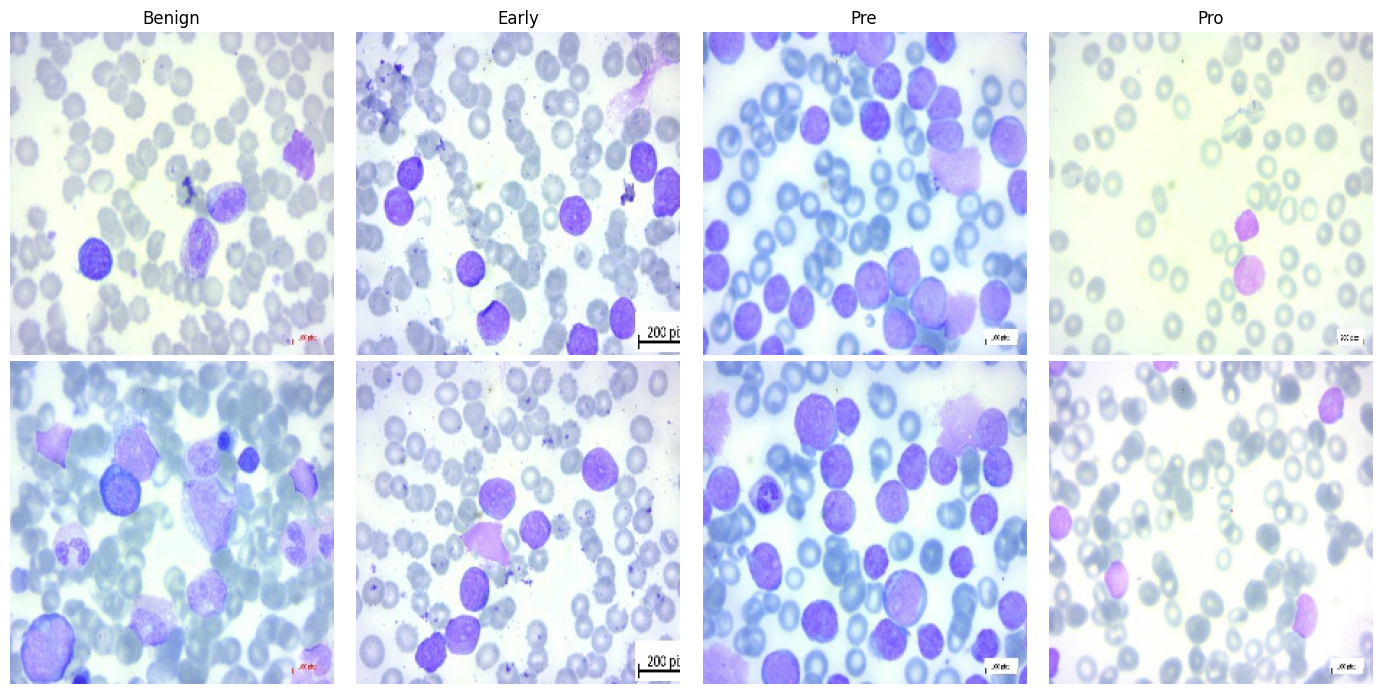

In [33]:
leer = lambda ruta: cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB)     # OpenCV lee en BGR: lo pasamos a RGB para mostrar
subtipos = sorted(org.subtipo.unique())
fig, ax = plt.subplots(2, len(subtipos), figsize=(3.5 * len(subtipos), 7))
for j, st in enumerate(subtipos):
    for i, r in enumerate(org[org.subtipo == st].sample(2, random_state=0).itertuples()):
        ax[i, j].imshow(leer(r.ruta)); ax[i, j].axis('off')
    ax[0, j].set_title(st)
plt.tight_layout()

### 1.2 Características globales de cada imagen
En una sola pasada por todas las imágenes originales calculamos:
- **resolución** y **formato**;
- **medias de color** en HSV y CIE Lab (para estudiar la variabilidad de tinción entre muestras);
- **uniformidad de la iluminación**: estimamos el *campo de iluminación* del canal V (el brillo del fondo sin las células) y medimos su coeficiente de variación (CV = σ/μ) y el cociente centro/borde. Un campo uniforme tiene CV ≈ 0 y centro/borde ≈ 1; el viñeteo típico del microscopio da centro/borde > 1;
- **histogramas** RGB y HSV acumulados por clase.

El campo se estima con un **cierre morfológico** (dilatación seguida de erosión) con un elemento estructurante más grande que las células: como las células son más oscuras que el fondo, el cierre las "borra" y deja sólo la iluminación de fondo. Un suavizado gaussiano final evita escalones. Esta misma función se reutiliza en la corrección (sección 2).

Las medias cromáticas se calculan sobre la imagen completa y se utilizan como indicadores descriptivos de variabilidad global entre muestras. Dado que incluyen simultáneamente fondo y estructuras celulares, no deben interpretarse como medidas específicas de la tinción nuclear. La caracterización cromática de los núcleos se realizará posteriormente sobre las regiones segmentadas.

La estimación del campo de iluminación se realiza inicialmente con los parámetros definidos en la implementación original, que se consideran una configuración de referencia y serán sometidos a un análisis de sensibilidad.

In [34]:
# Parámetros originales del grupo, conservados como línea de base.
TAM_EE = 1 / 3

def estimar_campo(v, metodo='cierre',
                  tam_ee=None, sigma_gauss=None,
                  sigma_cierre=None):
    """
    Estima el campo de iluminación a partir del canal V.

    gauss: suavizado de escala amplia.
    cierre: cierre morfológico seguido de suavizado.

    Los parámetros pueden modificarse para realizar
    un análisis de sensibilidad.
    """
    v = v.astype(np.float32)
    n = max(v.shape)

    if tam_ee is None:
        tam_ee = int(n * TAM_EE) | 1

    if sigma_gauss is None:
        sigma_gauss = n / 4

    if sigma_cierre is None:
        sigma_cierre = n / 16

    if metodo == 'gauss':
        return cv2.GaussianBlur(
            v, (0, 0), sigmaX=sigma_gauss
        )

    elif metodo == 'cierre':
        tam_ee = max(3, int(tam_ee) | 1)

        ee = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (tam_ee, tam_ee)
        )

        campo = cv2.morphologyEx(
            v, cv2.MORPH_CLOSE, ee
        )

        return cv2.GaussianBlur(
            campo, (0, 0), sigmaX=sigma_cierre
        )

    else:
        raise ValueError("Método no reconocido")
def centro_borde(campo):
    """Cociente entre el brillo medio del centro y el de un marco de 1/8 de la imagen."""
    b = max(campo.shape) // 8
    marco = np.ones(campo.shape, bool); marco[b:-b, b:-b] = False
    h, w = campo.shape
    return campo[h//2 - b:h//2 + b, w//2 - b:w//2 + b].mean() / campo[marco].mean()

def histogramas(rgb, hsv):
    """Histogramas normalizados de R, G, B, H, S, V -> [6 x 256]."""
    return np.array([np.bincount(c.ravel(), minlength=256)[:256] / c.size
                     for c in np.concatenate([rgb, hsv], axis=2).transpose(2, 0, 1)])

filas, hist = [], {c: 0 for c in org.clase.unique()}
for r in org.itertuples():
    rgb = leer(r.ruta)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)       # OpenCV: H en [0, 180), S y V en [0, 255]
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)       # OpenCV: a* y b* desplazados +128 (128 = neutro)
    campo = estimar_campo(hsv[..., 2].astype(np.float32))
    filas.append(dict(alto=rgb.shape[0], ancho=rgb.shape[1], ext=os.path.splitext(r.ruta)[1].lower(),
                      H=hsv[..., 0].mean(), S=hsv[..., 1].mean(), V=hsv[..., 2].mean(),
                      V_sat=(hsv[..., 2] == 255).mean(),           # fracción de píxeles saturados (fondo "quemado")
                      a=lab[..., 1].mean() - 128, b=lab[..., 2].mean() - 128,
                      cv_campo=campo.std() / campo.mean(), centro_borde=centro_borde(campo)))
    hist[r.clase] = hist[r.clase] + histogramas(rgb, hsv)
desc = pd.concat([org[['subtipo', 'clase']], pd.DataFrame(filas)], axis=1)

print('Resoluciones (alto x ancho):', desc.groupby(['alto', 'ancho']).size().to_dict())
print('Formatos:', desc.ext.value_counts().to_dict())

print(
    "Imágenes con CV del campo estimado > 1 % "
    "(criterio exploratorio): "
    f"{(desc.cv_campo > 0.01).mean():.1%}"
)

desc.groupby('clase')[['H', 'S', 'V', 'V_sat', 'a', 'b', 'cv_campo', 'centro_borde']].agg(['mean', 'std']).round(3)

Resoluciones (alto x ancho): {(224, 224): 3256}
Formatos: {'.jpg': 3256}
Imágenes con CV del campo estimado > 1 % (criterio exploratorio): 3.3%


H               S                V         V_sat         \
                 mean     std    mean     std     mean    std   mean    std   
clase                                                                         
no patológica  89.805   8.958  31.525  10.763  236.382  6.774  0.192  0.086   
patológica     92.540  12.796  39.011  18.106  242.919  4.483  0.275  0.083   

                   a              b        cv_campo        centro_borde         
                mean    std    mean    std     mean    std         mean    std  
clase                                                                           
no patológica  1.703  3.643  -7.977  4.106    0.005  0.009        1.003  0.007  
patológica     2.545  2.783 -12.216  8.146    0.002  0.003        1.001  0.003

### 1.3 Histogramas RGB y HSV por clase
Histograma medio de cada canal para benignas vs. patológicas. Diferencias marcadas (p. ej. en H o S) anticipan qué canales conviene usar para separar el núcleo en la segmentación.

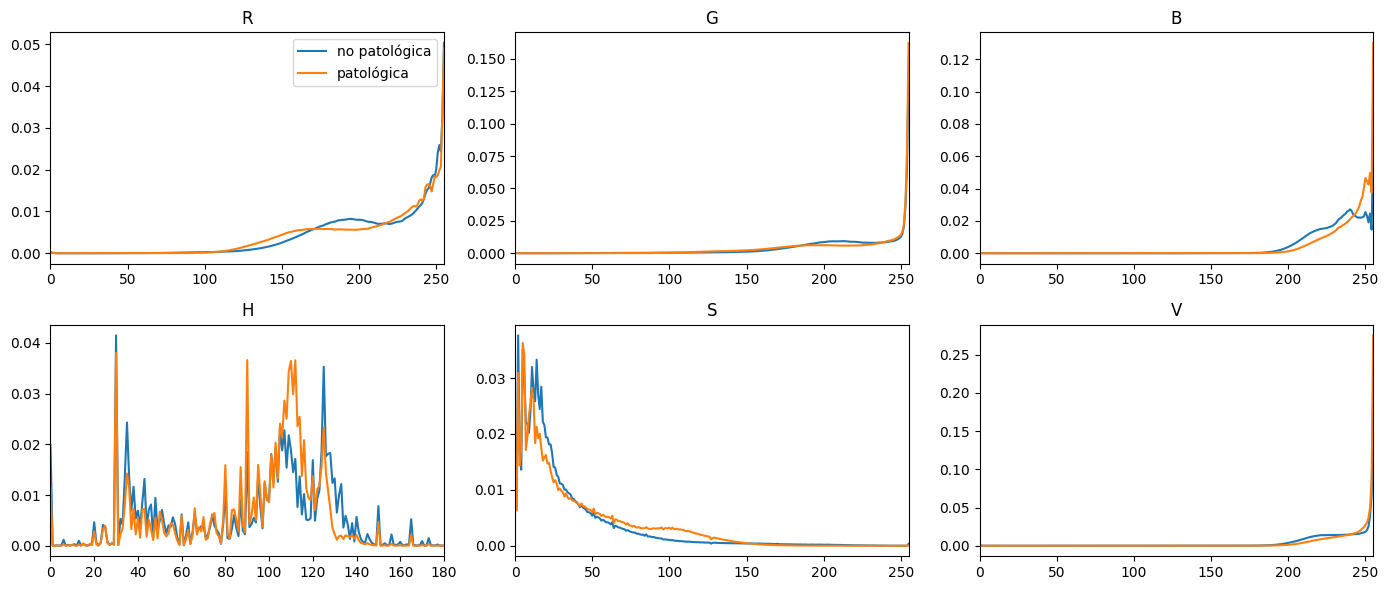

In [35]:
nombres = ['R', 'G', 'B', 'H', 'S', 'V']
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for k, a in enumerate(ax.ravel()):
    for clase, h in hist.items():
        a.plot(h[k] / (org.clase == clase).sum(), label=clase)        # promedio de los histogramas de la clase
    a.set(title=nombres[k], xlim=(0, 180 if nombres[k] == 'H' else 255))
ax[0, 0].legend(); plt.tight_layout()

### 1.4 Iluminación y tinción
- **Iluminación**: distribución del CV del campo y del cociente centro/borde. Se analiza la distribución del coeficiente de variación del campo de iluminación estimado y del cociente entre las intensidades medias del centro y los bordes. Valores bajos de CV y cocientes cercanos a la unidad sugieren una iluminación aproximadamente uniforme, aunque su interpretación depende de la calidad de la estimación del campo. La necesidad de aplicar una corrección se evaluará mediante la comparación de los métodos de preprocesamiento y su efecto posterior sobre la segmentación.
- **Tinción**: dispersión de las medias de H, S, a\* y b\* por subtipo. Mucha dispersión dentro de un mismo subtipo indica variabilidad de tinción entre muestras, que puede afectar umbrales fijos en la segmentación.

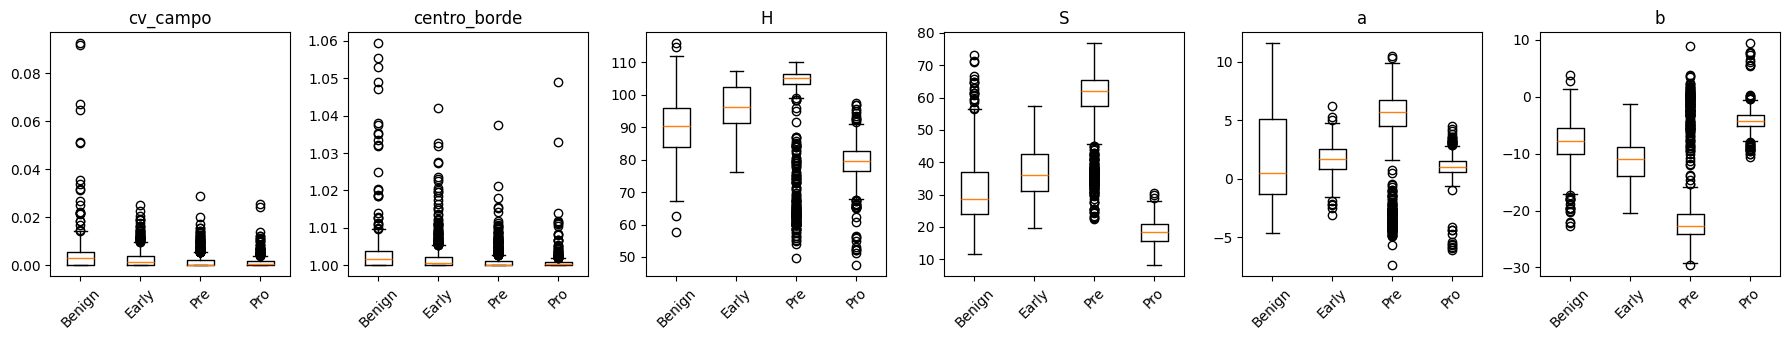

In [36]:
fig, ax = plt.subplots(1, 6, figsize=(18, 3.5))
for a, var in zip(ax, ['cv_campo', 'centro_borde', 'H', 'S', 'a', 'b']):
    a.boxplot([desc.loc[desc.subtipo == st, var] for st in subtipos])
    a.set_xticks(range(1, len(subtipos) + 1), subtipos, rotation=45)
    a.set_title(var)
plt.tight_layout()

## 2. Corrección de iluminación
Tres alternativas sobre el canal V, comparadas con la imagen sin corregir:

| Método | Qué hace |
|---|---|
| `gauss` | campo = gaussiano de escala amplia; **V / campo** (normalización por el fondo) |
| `cierre` | campo = cierre morfológico; **V / campo** |
| `clahe` | ecualización adaptativa de histograma con límite de contraste (realza contraste local, no estima el campo) |

En la normalización, al dividir por el campo se cancela la iluminación no uniforme, y al multiplicar por su media se conserva el brillo global.

In [37]:
METODOS = ['ninguno', 'gauss', 'cierre', 'clahe']

def preprocesar(rgb, metodo='cierre',
               tam_ee=None, sigma_gauss=None,
               sigma_cierre=None,
               clip_limit=2.0, tile_grid=(8, 8)):
    """
    Procesamiento sobre el canal V del espacio HSV.

    Mantiene H y S sin modificar directamente.
    Permite ajustar los parámetros de cada método.
    """
    if metodo not in METODOS:
        raise ValueError("Método no reconocido")

    h, s, v = cv2.split(
        cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    )

    if metodo == 'clahe':
        clahe = cv2.createCLAHE(
            clipLimit=clip_limit,
            tileGridSize=tile_grid
        )
        v = clahe.apply(v)

    elif metodo in ['gauss', 'cierre']:
        campo = estimar_campo(
            v.astype(np.float32),
            metodo=metodo,
            tam_ee=tam_ee,
            sigma_gauss=sigma_gauss,
            sigma_cierre=sigma_cierre
        )

        campo = np.maximum(campo, 1.0)

        v = np.clip(
            v.astype(np.float32) / campo * campo.mean(),
            0, 255
        ).astype(np.uint8)

    return cv2.cvtColor(
        cv2.merge([h, s, v]),
        cv2.COLOR_HSV2RGB
    )

### 2.1 Comparación visual y perfiles de iluminación

Se comparan visualmente los resultados de los cuatro métodos sobre la imagen con mayor coeficiente de variación del campo estimado. Para cada alternativa se obtiene el perfil horizontal del campo de iluminación estimado después del procesamiento.

Un perfil aproximadamente constante sugiere una mayor uniformidad espacial de la iluminación estimada. Sin embargo, esta observación debe interpretarse junto con la apariencia de las estructuras celulares y las métricas cuantitativas, ya que la uniformidad del perfil no garantiza por sí sola una mejora de la calidad de imagen.

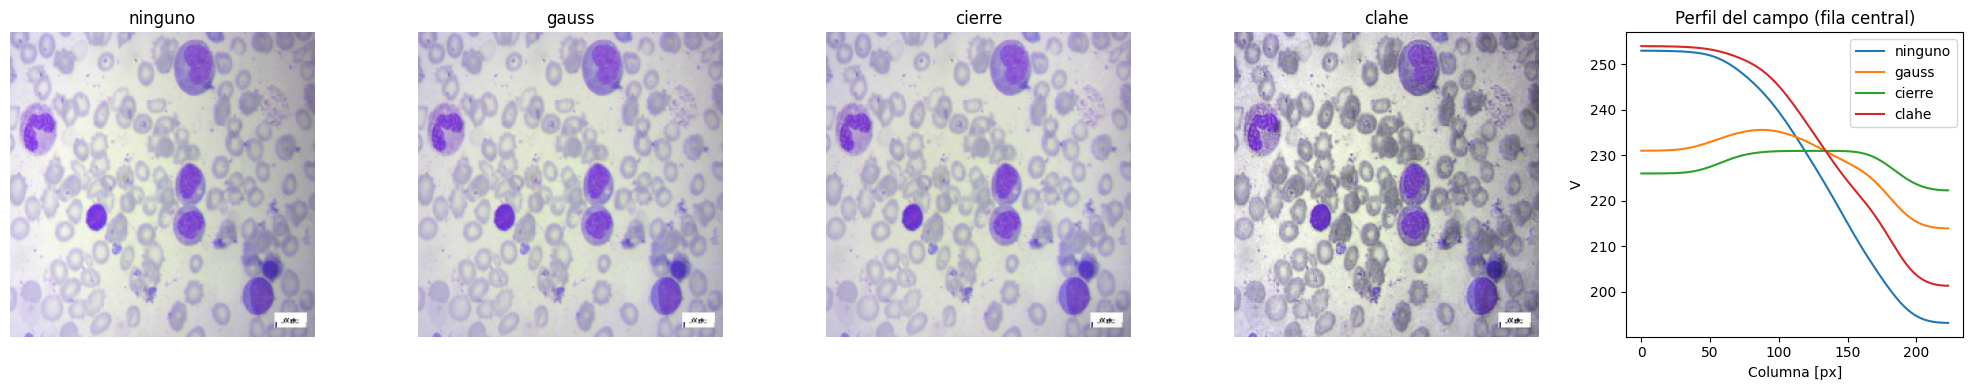

In [38]:
ej = leer(org.ruta[desc.cv_campo.idxmax()])          # la imagen con iluminación menos uniforme del dataset
fig, ax = plt.subplots(1, len(METODOS) + 1, figsize=(20, 4))
for a, m in zip(ax, METODOS):
    corr = preprocesar(ej, m)
    campo = estimar_campo(cv2.cvtColor(corr, cv2.COLOR_RGB2HSV)[..., 2].astype(np.float32))
    a.imshow(corr); a.set_title(m); a.axis('off')
    ax[-1].plot(campo[campo.shape[0] // 2], label=m)
ax[-1].set(title='Perfil del campo (fila central)', xlabel='Columna [px]', ylabel='V'); ax[-1].legend()
plt.tight_layout()

### 2.2 Comparación cuantitativa
Medimos cada método sobre dos grupos: una **muestra aleatoria** estratificada (150 benignas + 150 patológicas) y **todas las imágenes no uniformes** (CV del campo > 1 %), que son donde la corrección debería notarse.
- **cv_fondo**: dispersión del brillo en el fondo (σ/μ de V). Cuanto menor, más uniforme quedó la iluminación.
- **contraste**: contraste núcleo–fondo $(g_f - g_n)/(g_f + g_n)$ en **escala de grises**. Conviene que no baje.
- **detalle_nuclear**: coeficiente de variación de la intensidad en escala de grises dentro de la región nuclear aproximada. Permite cuantificar modificaciones en la distribución de intensidades producidas por el preprocesamiento, pero no distingue por sí solo entre detalles estructurales de la cromatina y ruido.

El contraste se mide en gris y no en V porque **en este dataset el núcleo no es oscuro en V**: V = máx(R, G, B) y el violeta del núcleo tiene el azul alto, así que su V (≈ 240) es casi igual al del fondo. El núcleo se separa por **saturación y tono** (S y H), y en luminancia.

Las regiones se aproximan **en la imagen original**, para comparar todos los métodos sobre los mismos píxeles: fondo = 30 % de píxeles menos saturados (plasma) y núcleo = 5 % más saturados (violeta intenso). Es una aproximación rápida; la segmentación real es el Módulo 2.

**Limitaciones de la evaluación:** las regiones de fondo y núcleo utilizadas para calcular las métricas se estiman a partir de percentiles de saturación y no constituyen máscaras anatómicas validadas. Por este motivo, los resultados deben interpretarse como una comparación exploratoria entre métodos de preprocesamiento.

Asimismo, un aumento de la variabilidad de intensidad dentro del núcleo no implica necesariamente amplificación de ruido, ya que puede representar un realce de la textura de la cromatina. La selección definitiva del método requerirá complementar estas métricas con inspección visual y con la evaluación posterior de la calidad de segmentación.

In [39]:

def regiones(rgb, p_fondo=30, p_nucleo=95):
    """
    Regiones aproximadas a partir de saturación HSV.

    Los percentiles son criterios exploratorios,
    no una segmentación nuclear validada.
    """
    s = cv2.cvtColor(
        rgb, cv2.COLOR_RGB2HSV
    )[..., 1].astype(np.float32)

    t_fondo = np.percentile(s, p_fondo)
    t_nucleo = np.percentile(s, p_nucleo)

    # Incluye empates para evitar máscaras vacías
    # cuando varios píxeles tienen igual saturación.
    fondo = s <= t_fondo
    nucleo = s >= t_nucleo

    if not fondo.any() or not nucleo.any():
        raise ValueError("Región de evaluación vacía")

    return fondo, nucleo


def metricas(rgb, fondo, nucleo):
    """
    Métricas exploratorias del preprocesamiento.
    Las máscaras permanecen fijas para comparar métodos.
    """
    v = cv2.cvtColor(
        rgb, cv2.COLOR_RGB2HSV
    )[..., 2].astype(np.float64)

    g = cv2.cvtColor(
        rgb, cv2.COLOR_RGB2GRAY
    ).astype(np.float64)

    gf = g[fondo].mean()
    gn = g[nucleo].mean()
    vf = v[fondo].mean()

    eps = 1e-8

    return dict(
        cv_fondo=v[fondo].std() / max(vf, eps),
        contraste=(gf - gn) / max(gf + gn, eps),
        detalle_nuclear=g[nucleo].std() / max(gn, eps)
    )


In [40]:

# Comparación cuantitativa exploratoria

muestra_300 = org.groupby(
    'clase', group_keys=False
).sample(n=150, random_state=42)

# Imágenes con mayor variación del campo estimado
no_uniformes = org.loc[
    desc.cv_campo > 0.01
]

grupos = {
    'Muestra estratificada': muestra_300,
    'CV campo > 1%': no_uniformes
}

resultados_metodos = []

for nombre_grupo, grupo in grupos.items():
    for r in grupo.itertuples():
        rgb = leer(r.ruta)
        fondo, nucleo = regiones(rgb)

        for metodo in METODOS:
            corregida = preprocesar(rgb, metodo)

            met = metricas(
                corregida, fondo, nucleo
            )

            resultados_metodos.append({
                'grupo': nombre_grupo,
                'metodo': metodo,
                'ruta': r.ruta,
                **met
            })

res_metodos = pd.DataFrame(resultados_metodos)

tabla_metodos = res_metodos.groupby(
    ['grupo', 'metodo']
)[[
    'cv_fondo',
    'contraste',
    'detalle_nuclear'
]].agg(['mean', 'std'])

display(tabla_metodos.round(4))


cv_fondo         contraste          \
                                  mean     std      mean     std   
grupo                 metodo                                       
CV campo > 1%         cierre    0.0411  0.0187    0.2738  0.0758   
                      clahe     0.0861  0.0315    0.3022  0.0791   
                      gauss     0.0414  0.0185    0.2715  0.0749   
                      ninguno   0.0480  0.0205    0.2720  0.0761   
Muestra estratificada cierre    0.0374  0.0204    0.2635  0.0773   
                      clahe     0.0696  0.0334    0.2877  0.0782   
                      gauss     0.0369  0.0203    0.2628  0.0772   
                      ninguno   0.0383  0.0203    0.2633  0.0775   

                              detalle_nuclear          
                                         mean     std  
grupo                 metodo                           
CV campo > 1%         cierre           0.1321  0.0526  
                      clahe            0.1888  0.0591  
                      gauss            0.1320  0.0520  
                      ninguno          0.1336  0.0522  
Muestra estratificada cierre           0.1414  0.0623  
                      clahe            0.1830  0.0616  
                      gauss            0.1407  0.0622  
                      ninguno          0.1413  0.0622

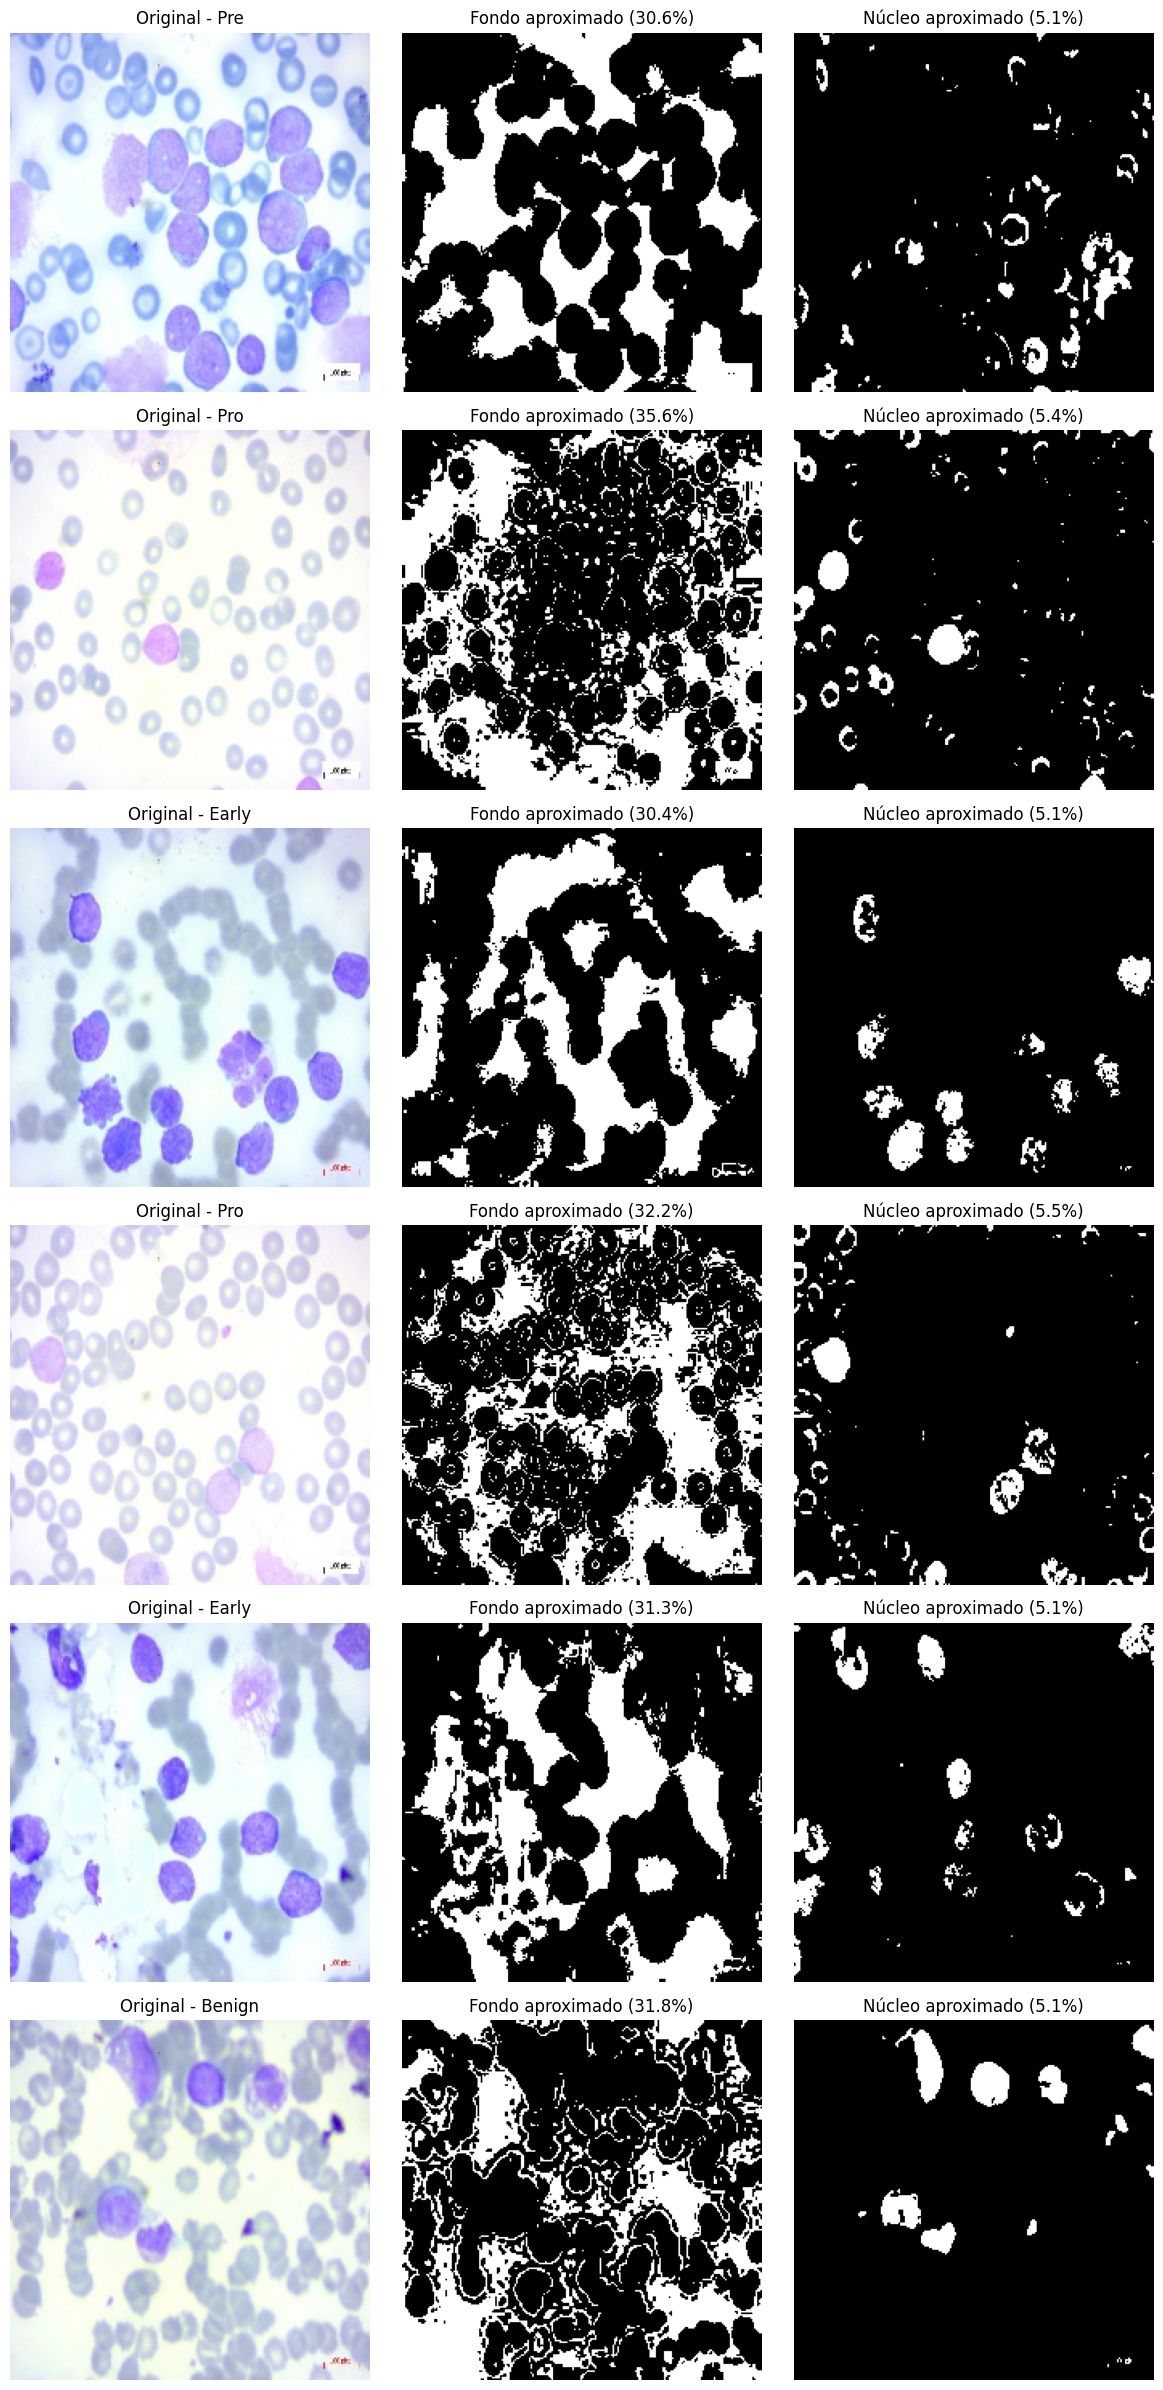

In [41]:

# Verificación visual de las regiones aproximadas
rng = np.random.default_rng(42)

indices = rng.choice(
    len(org),
    size=min(6, len(org)),
    replace=False
)

fig, ax = plt.subplots(
    len(indices), 3,
    figsize=(12, 4 * len(indices))
)

ax = np.atleast_2d(ax)

for i, idx in enumerate(indices):
    rgb = leer(org.iloc[idx].ruta)
    fondo, nucleo = regiones(rgb)

    ax[i, 0].imshow(rgb)
    ax[i, 0].set_title(
        f"Original - {org.iloc[idx].subtipo}"
    )

    ax[i, 1].imshow(fondo, cmap='gray',
                    vmin=0, vmax=1)
    ax[i, 1].set_title(
        f"Fondo aproximado ({fondo.mean():.1%})"
    )

    ax[i, 2].imshow(nucleo, cmap='gray',
                    vmin=0, vmax=1)
    ax[i, 2].set_title(
        f"Núcleo aproximado ({nucleo.mean():.1%})"
    )

    for a in ax[i]:
        a.axis('off')

plt.tight_layout()
plt.show()


### 2.3 Análisis de sensibilidad de los parámetros

Se realiza un barrido exploratorio de parámetros para evaluar la estabilidad de las métricas obtenidas mediante los distintos métodos de preprocesamiento. Se selecciona una muestra reproducible y balanceada de 80 imágenes, con 40 imágenes benignas y 40 patológicas.

Se analizan distintas escalas de suavizado gaussiano, tamaños de elementos estructurantes para el cierre morfológico y configuraciones de CLAHE.

El objetivo de este análisis no es determinar un conjunto definitivo de parámetros óptimos, sino identificar la sensibilidad de los resultados frente a distintas configuraciones. La selección final del procesamiento se realizará considerando también la calidad de segmentación nuclear evaluada en el Módulo 2.

In [42]:

from itertools import product

# Muestra exploratoria balanceada
muestra = org.groupby('clase', group_keys=False).sample(
    n=40, random_state=42
)

# Candidatos: incluimos configuraciones originales
configs = [
    dict(metodo='ninguno', nombre='ninguno')
]

for tam, sigma in product(
    [25, 35, 51, 75, 101],
    [8, 14]
):
    configs.append(dict(
        metodo='cierre',
        tam_ee=tam,
        sigma_cierre=sigma,
        nombre=f'cierre_EE{tam}_s{sigma}'
    ))

for sigma in [14, 28, 42, 56]:
    configs.append(dict(
        metodo='gauss',
        sigma_gauss=sigma,
        nombre=f'gauss_s{sigma}'
    ))

for clip, tile in product(
    [1.0, 2.0, 3.0],
    [4, 8]
):
    configs.append(dict(
        metodo='clahe',
        clip_limit=clip,
        tile_grid=(tile, tile),
        nombre=f'clahe_c{clip}_t{tile}'
    ))

resultados = []

for r in muestra.itertuples():
    rgb = leer(r.ruta)
    fondo, nucleo = regiones(rgb)

    for config in configs:
        nombre = config['nombre']
        kwargs = {
            k: v for k, v in config.items()
            if k != 'nombre'
        }

        corregida = preprocesar(rgb, **kwargs)
        met = metricas(corregida, fondo, nucleo)

        resultados.append(dict(
            ruta=r.ruta,
            clase=r.clase,
            configuracion=nombre,
            **met
        ))

barrido = pd.DataFrame(resultados)

resumen = barrido.groupby(
    'configuracion'
)[['cv_fondo', 'contraste',
   'detalle_nuclear']].agg(['mean', 'std'])

display(resumen.round(4))


cv_fondo         contraste         detalle_nuclear        
                     mean     std      mean     std            mean     std
configuracion                                                              
cierre_EE101_s14   0.0397  0.0218    0.2614  0.0724          0.1412  0.0633
cierre_EE101_s8    0.0397  0.0218    0.2614  0.0724          0.1412  0.0633
cierre_EE25_s14    0.0375  0.0221    0.2618  0.0721          0.1406  0.0637
cierre_EE25_s8     0.0372  0.0221    0.2618  0.0722          0.1407  0.0638
cierre_EE35_s14    0.0379  0.0220    0.2618  0.0722          0.1409  0.0636
cierre_EE35_s8     0.0378  0.0220    0.2618  0.0722          0.1409  0.0637
cierre_EE51_s14    0.0385  0.0218    0.2617  0.0722          0.1411  0.0635
cierre_EE51_s8     0.0384  0.0219    0.2618  0.0722          0.1411  0.0635
cierre_EE75_s14    0.0392  0.0218    0.2615  0.0723          0.1412  0.0635
cierre_EE75_s8     0.0392  0.0218    0.2615  0.0723          0.1413  0.0635
clahe_c1.0_t4      0.0592  0.0302    0.2745  0.0734          0.1613  0.0630
clahe_c1.0_t8      0.0543  0.0282    0.2728  0.0731          0.1574  0.0637
clahe_c2.0_t4      0.0808  0.0414    0.2886  0.0756          0.1916  0.0678
clahe_c2.0_t8      0.0724  0.0353    0.2865  0.0747          0.1830  0.0646
clahe_c3.0_t4      0.1007  0.0506    0.3020  0.0790          0.2254  0.0780
clahe_c3.0_t8      0.0881  0.0428    0.2996  0.0770          0.2116  0.0724
gauss_s14          0.0371  0.0210    0.2594  0.0718          0.1382  0.0640
gauss_s28          0.0376  0.0215    0.2604  0.0719          0.1396  0.0637
gauss_s42          0.0381  0.0216    0.2606  0.0720          0.1402  0.0635
gauss_s56          0.0385  0.0216    0.2607  0.0721          0.1405  0.0633
ninguno            0.0402  0.0217    0.2614  0.0725          0.1412  0.0632

In [43]:

# Comparación de las configuraciones exploradas

base = barrido[
    barrido.configuracion == 'ninguno'
][['ruta', 'cv_fondo', 'contraste',
   'detalle_nuclear']].rename(columns={
       'cv_fondo': 'cv_base',
       'contraste': 'contraste_base',
       'detalle_nuclear': 'detalle_base'
   })

comparacion = barrido.merge(base, on='ruta')

comparacion['delta_cv'] = (
    comparacion.cv_fondo - comparacion.cv_base
)
comparacion['delta_contraste'] = (
    comparacion.contraste -
    comparacion.contraste_base
)
comparacion['delta_detalle'] = (
    comparacion.detalle_nuclear -
    comparacion.detalle_base
)

resumen_delta = comparacion.groupby(
    'configuracion'
)[['delta_cv', 'delta_contraste',
   'delta_detalle']].mean().sort_values(
       'delta_cv'
   )

display(resumen_delta.round(4))


,delta_cv,delta_contraste,delta_detalle
configuracion,,,
gauss_s14,-0.0031,-0.0020,-0.0029
cierre_EE25_s8,-0.0030,0.0004,-0.0004
cierre_EE25_s14,-0.0028,0.0004,-0.0005
gauss_s28,-0.0026,-0.0011,-0.0016
cierre_EE35_s8,-0.0025,0.0004,-0.0002
cierre_EE35_s14,-0.0023,0.0003,-0.0003
gauss_s42,-0.0021,-0.0008,-0.0010
cierre_EE51_s8,-0.0018,0.0003,-0.0000
cierre_EE51_s14,-0.0017,0.0003,-0.0000


In [44]:

# Control de reproducibilidad del preprocesamiento original
rgb = leer(org.iloc[0].ruta)

pares = [
    (
        preprocesar(rgb, 'gauss'),
        preprocesar(rgb, 'gauss',
                   sigma_gauss=56)
    ),
    (
        preprocesar(rgb, 'cierre'),
        preprocesar(rgb, 'cierre',
                   tam_ee=75,
                   sigma_cierre=14)
    ),
    (
        preprocesar(rgb, 'clahe'),
        preprocesar(rgb, 'clahe',
                   clip_limit=2.0,
                   tile_grid=(8, 8))
    )
]

for metodo, (a, b) in zip(
    ['gauss', 'cierre', 'clahe'], pares
):
    diferencia = np.abs(
        a.astype(int) - b.astype(int)
    ).max()

    print(metodo, 'diferencia máxima:', diferencia)
    assert diferencia == 0


gauss diferencia máxima: 0
cierre diferencia máxima: 0
clahe diferencia máxima: 0


## 3. Conclusiones del Módulo 1
*(Corrida sobre las 3.256 imágenes originales.)*

**Dataset**
- 3.256 imágenes JPG de 224 × 224 px, todas con su segmentación de referencia. Son campos con muchas células (no recortes de una sola célula).
- Desbalance marcado: 15,5 % benignas (504) vs. 84,5 % patológicas (2.752). Va a haber que tenerlo en cuenta en la división ajuste/prueba y al reportar métricas.
- Muchas imágenes tienen una **marca de agua o barra de escala en la esquina inferior derecha**. En la segmentación hay que descartar los objetos de esa zona.

**Iluminación**

El análisis inicial del canal V del espacio HSV mostró una dispersión reducida del campo de iluminación estimado en gran parte del conjunto de imágenes. Utilizando como criterio exploratorio un coeficiente de variación superior al 1 %, se identificó un subconjunto de imágenes con mayor variabilidad de intensidad. Sin embargo, este valor no constituye un umbral universal de iluminación no uniforme y su interpretación depende del procedimiento utilizado para estimar el campo.

Se compararon cuatro condiciones de procesamiento: imagen original, corrección mediante filtro gaussiano, corrección mediante cierre morfológico y aplicación de CLAHE.

Los resultados preliminares mostraron que los métodos gaussiano y morfológico producen reducciones moderadas en la dispersión del fondo, mientras que CLAHE aumenta el contraste local, acompañado de un incremento de la variabilidad de intensidad.

Dado que los resultados dependen de los parámetros utilizados, se incorporó un análisis de sensibilidad para comparar diferentes escalas de suavizado, tamaños de elementos estructurantes y configuraciones de CLAHE.

El análisis de sensibilidad (sección 2.3) confirma esta tendencia en un barrido más amplio de parámetros: el cierre morfológico y el gaussiano son los únicos que bajan la dispersión del fondo de forma consistente, sin costo en contraste ni en detalle nuclear, mientras que CLAHE la empeora en todas las configuraciones probadas. **Decisión: se aplica el cierre morfológico a todas las imágenes** (en las ya uniformes no cambia el resultado, y en las que no lo son corrige la dispersión del fondo); es el método usado en el resto del trabajo (Módulos 2 y 3).

**Color y tinción**

La caracterización global de las imágenes permitió identificar diferencias en las distribuciones cromáticas de las clases y subtipos presentes en el dataset.

Las diferencias observadas en saturación y en los componentes cromáticos del espacio Lab respaldan la utilización de información de color para la segmentación, particularmente mediante técnicas basadas en HSV y agrupamiento sobre las componentes a* y b*.

No obstante, estas estadísticas corresponden a la imagen completa y no exclusivamente al núcleo celular. Por lo tanto, las diferencias encontradas pueden estar influenciadas por la proporción de fondo, la presencia de eritrocitos, las condiciones de adquisición y la variabilidad de tinción.

En consecuencia, la evaluación específica de las características cromáticas nucleares se realizará una vez obtenidas las máscaras de segmentación.

In [45]:
# Decisión final (ver conclusiones): el cierre morfológico reduce la dispersión del
# fondo sin costo en contraste ni detalle nuclear, confirmado por el análisis de
# sensibilidad de 2.3. Es el método usado en el resto del trabajo (Módulos 2 y 3).

METODO_ELEGIDO = 'cierre'

# Conservamos los descriptores originales
desc.to_csv(
    'modulo1_descriptores_globales.csv',
    index=False
)

# Guardamos los resultados del barrido
barrido.to_csv(
    'modulo1_barrido_parametros.csv',
    index=False
)